In [3]:
!pip install torch

  Using cached triton-3.2.0-cp39-cp39-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (1.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 51.7 MB/s eta 0:00:0000:0100:01
Using cached triton-3.2.0-cp39-cp39-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (253.1 MB)
  Attempting uninstall: nvidia-nccl-cu12
    Found existing installation: nvidia-nccl-cu12 2.29.7
    Uninstalling nvidia-nccl-cu12-2.29.7:
      Successfully uninstalled nvidia-nccl-cu12-2.29.7


In [1]:
import pandas as pd
import biom
import torch

# from microbiome_model.data.dataset import DataProcessor, Arguments
# from microbiome_model.data.dataset_sparse import collate_fn as sparse_collate_fn
# from microbiome_model.models.orig import BasicRegressor
# from microbiome_model.eval.evaluate import predict
# import matplotlib.pyplot as plt


In [2]:
state_dict = torch.load("../results/age_prediction/gut_data/rel_abundanceeee_works/seed_1/best_model.pt", map_location="cpu")
for k, v in state_dict.items():
    print(k, v.shape)

query_vector torch.Size([1, 1, 256])
_count_alpha torch.Size([1])
query_vectors torch.Size([1, 1, 256])
scale_embeddings.0.weight torch.Size([256, 768])
scale_embeddings.0.bias torch.Size([256])
scale_embeddings.2.weight torch.Size([256, 256])
scale_embeddings.2.bias torch.Size([256])
scale_embeddings.3.weight torch.Size([256])
scale_embeddings.3.bias torch.Size([256])
pos_embedding.position_embeddings.weight torch.Size([5000, 256])
sequence_encoder.self_attn.in_proj_weight torch.Size([768, 256])
sequence_encoder.self_attn.in_proj_bias torch.Size([768])
sequence_encoder.self_attn.out_proj.weight torch.Size([256, 256])
sequence_encoder.self_attn.out_proj.bias torch.Size([256])
sequence_encoder.linear1.weight torch.Size([768, 256])
sequence_encoder.linear1.bias torch.Size([768])
sequence_encoder.linear2.weight torch.Size([256, 768])
sequence_encoder.linear2.bias torch.Size([256])
sequence_encoder.norm1.weight torch.Size([256])
sequence_encoder.norm1.bias torch.Size([256])
sequence_encode

In [2]:
state_dict = torch.load("../results/multitask_all_nope_bimonth_env_features/D30/run_1/model.pt", map_location="cpu")
for k, v in state_dict.items():
    print(k, v.shape)

query_vector torch.Size([1, 1, 128])
_count_alpha torch.Size([1])
scale_embeddings.0.weight torch.Size([256, 768])
scale_embeddings.0.bias torch.Size([256])
scale_embeddings.2.weight torch.Size([128, 256])
scale_embeddings.2.bias torch.Size([128])
scale_embeddings.3.weight torch.Size([128])
scale_embeddings.3.bias torch.Size([128])
sequence_encoder.self_attn.in_proj_weight torch.Size([384, 128])
sequence_encoder.self_attn.in_proj_bias torch.Size([384])
sequence_encoder.self_attn.out_proj.weight torch.Size([128, 128])
sequence_encoder.self_attn.out_proj.bias torch.Size([128])
sequence_encoder.linear1.weight torch.Size([1024, 128])
sequence_encoder.linear1.bias torch.Size([1024])
sequence_encoder.linear2.weight torch.Size([128, 1024])
sequence_encoder.linear2.bias torch.Size([128])
sequence_encoder.norm1.weight torch.Size([128])
sequence_encoder.norm1.bias torch.Size([128])
sequence_encoder.norm2.weight torch.Size([128])
sequence_encoder.norm2.bias torch.Size([128])
sequence_attention.la

In [2]:
metadata_all = pd.read_csv("/s/chromatin/o/nobackup/Saira/Microbiome_Project/data/new_data/combined_metadata.tsv", sep="\t")

In [3]:
metadata_all[metadata_all["dataset_type"] == "test"]

,sample_name,season,host_subject_id,maggots,megyesi_score,sample_type,days_since_placement,body_site,add_0c,facility,project,dataset_type,env
2096,15700.hip.UTK.body1.spr2023.day2,spring,ARF_Body1,yes,3,skin,2,skin.hip,34.722222,ARF,PMIVAL,test,outdoor
2097,15700.hip.UTK.body1.spr2023.day5,spring,ARF_Body1,yes,8,skin,5,skin.hip,83.888889,ARF,PMIVAL,test,outdoor
2098,15700.hip.UTK.body1.spr2023.day8,spring,ARF_Body1,yes,15,skin,8,skin.hip,138.888889,ARF,PMIVAL,test,outdoor
2099,15700.hip.UTK.body1.spr2023.day11,spring,ARF_Body1,yes,15,skin,11,skin.hip,182.777778,ARF,PMIVAL,test,outdoor
2100,15700.hip.UTK.body1.spr2023.day14,spring,ARF_Body1,yes,12,skin,14,skin.hip,215.000000,ARF,PMIVAL,test,outdoor
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2316,15700.hip.WCU.body8.win2023.day11,winter,FOREST_Body8,no,3,skin,11,skin.hip,72.500000,FOREST,PMIVAL,test,outdoor
2317,15700.hip.WCU.body8.win2023.day14,winter,FOREST_Body8,no,4,skin,14,skin.hip,93.333333,FOREST,PMIVAL,test,outdoor
2318,15700.hip.WCU.body8.win2023.day17,winter,FOREST_Body8,no,6,skin,17,skin.hip,132.500000,FOREST,PMIVAL,test,outdoor
2319,15700.hip.WCU.body8.win2023.day20,winter,FOREST_Body8,no,9,skin,20,skin.hip,154.444444,FOREST,PMIVAL,test,outdoor


In [9]:
sample_to_donor = dict(zip(metadata_all["sample_name"], metadata_all["host_subject_id"]))

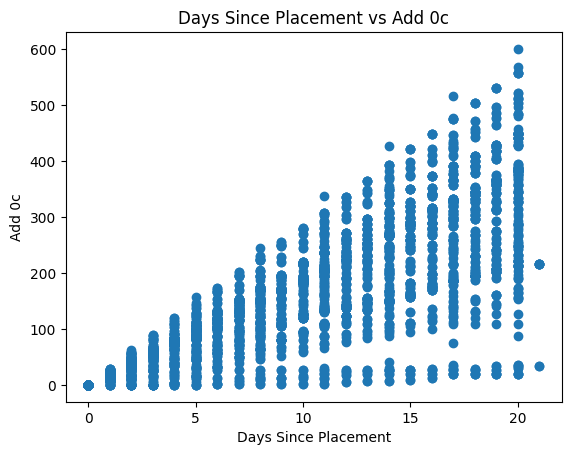

In [12]:
# plot days of days_since_placement vs add_0c
metadata_all["days_since_placement"] = metadata_all["days_since_placement"].fillna(0)
metadata_all["add_0c"] = metadata_all["add_0c"].fillna(0)
plt.scatter(metadata_all["days_since_placement"], metadata_all["add_0c"])
plt.xlabel("Days Since Placement")
plt.ylabel("Add 0c")
plt.title("Days Since Placement vs Add 0c")
plt.show()



Test set add_0c distribution:


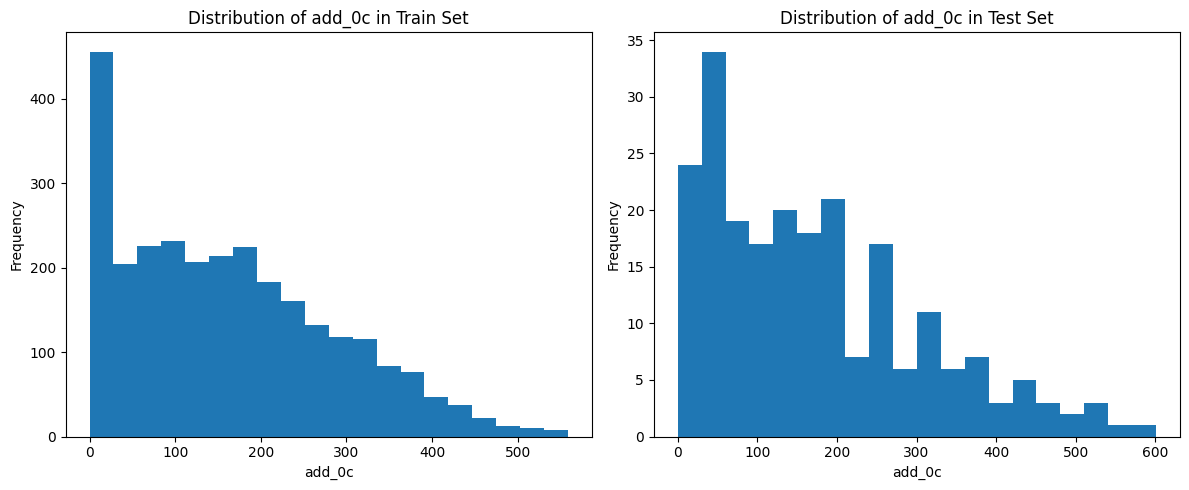

Min and max add_0c in test set: 0.0 600.8333333
Mean and std add_0c in test set: 173.0456790110578 134.83253608765526
Min and max add_0c in train set: 0.0 558.6111111
Mean and std add_0c in train set: 163.6583192858631 122.79396504592388


In [ ]:
# label distribution in test set
add_test = metadata_all[metadata_all["dataset_type"] == "test"]["add_0c"]
add_train = metadata_all[metadata_all["dataset_type"] == "train"]["add_0c"]
print("Test set add_0c distribution:")
# plot distribution
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].hist(add_train, bins=20)
ax[0].set_xlabel("add_0c")
ax[0].set_ylabel("Frequency")
ax[0].set_title("Distribution of add_0c in Train Set")
ax[1].hist(add_test, bins=20)
ax[1].set_xlabel("add_0c")
ax[1].set_ylabel("Frequency")
ax[1].set_title("Distribution of add_0c in Test Set")
plt.tight_layout()
plt.show()
print("Min and max add_0c in test set:", add_test.min(), add_test.max())
print("Mean and std add_0c in test set:", add_test.mean(), add_test.std())
print("Min and max add_0c in train set:", add_train.min(), add_train.max())
print("Mean and std add_0c in train set:", add_train.mean(), add_train.std())

In [30]:
biom_file = "../../process_data_all/exported-feature-table/feature-table.biom"
metadata_file = "../../data/new_data/combined_metadata_merged.tsv"
embedding_path = "../../data/embeddings/all_data.h5"
heldout = "D7"
res = "../results/multitask_all_nope_bimonth_env_features/"
res = "../results/all_data_abundance_proj_notanh_grl_ST2/D15/run_1/model.pt"

In [31]:
args = Arguments(
            biom_file=biom_file,
            metadata_file=metadata_file,
            tree_path=None,
            embedding_file=embedding_path,
            embedding="DNABERT",
            heldout=heldout,
            sort_asvs=True
                )
data_processor = DataProcessor(args)
data_processor.load_data(multitask=True, column="bi_month_name")

# PMI-val test pipeline
data_processor.load_test_data_pmival(column="bi_month_name")
test_dataset =  data_processor.sample_pmival_test_data() #data_processor.sample_test_data()
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=4, collate_fn=sparse_collate_fn)
            

Number of samples in metadata after filtering: 2747
Number of samples in targets after filtering: 2747
Number of indoor samples: 448
Number of outdoor samples: 2299
Number of samples after matching: 2747
Number of samples in pmival TEST after filtering: 225
Number of samples in metadata after filtering: 225
Number of pmival test samples: 225
In data loader  (28334, 177)


In [7]:
table = biom.load_table(biom_file)
ids = table.ids()

In [4]:
data_processor.sampleID_map_donorID

{'14989.skin.face.SHSU.2016.024.2016.04.16.day2': 'shsu.2016.024',
 '14989.skin.hip.SHSU.2016.024.2016.04.16.day2': 'shsu.2016.024',
 '14989.skin.face.UTK.K016.02.2016.04.16.day4': 'UTK.K016.02',
 '14989.skin.hip.UTK.K016.02.2016.04.16.day4': 'UTK.K016.02',
 '14989.skin.face.CMU.16.03.2016.02.25.day1': 'CMU_Mrs._16_03',
 '14989.skin.hip.CMU.16.03.2016.02.25.day1': 'CMU_Mrs._16_03',
 '14989.skin.face.CMU.16.03.2016.3.day2': 'CMU_Mrs._16_03',
 '14989.skin.hip.CMU.16.03.2016.3.day2': 'CMU_Mrs._16_03',
 '14989.skin.face.CMU.16.03.2016.3.day3': 'CMU_Mrs._16_03',
 '14989.skin.hip.CMU.16.03.2016.3.day3': 'CMU_Mrs._16_03',
 '14989.skin.face.CMU.16.03.2016.3.day4': 'CMU_Mrs._16_03',
 '14989.skin.hip.CMU.16.03.2016.3.day4': 'CMU_Mrs._16_03',
 '14989.skin.face.CMU.16.03.2016.3.day5': 'CMU_Mrs._16_03',
 '14989.skin.hip.CMU.16.03.2016.3.day5': 'CMU_Mrs._16_03',
 '14989.skin.face.CMU.16.03.2016.3.day6': 'CMU_Mrs._16_03',
 '14989.skin.hip.CMU.16.03.2016.3.day6': 'CMU_Mrs._16_03',
 '14989.skin.face.CM

In [17]:
best_run_dir = res + heldout + "/run_1/"

In [31]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#model = BasicRegressor(input_dim=128, pe=False)
#model.load_state_dict(torch.load(best_run_dir + "model.pt", map_location=device))
model = BasicRegressor(input_dim=256, hidden_dim=768, pe=False, grl=True, unique_donors_train=73)
model.load_state_dict(torch.load(res, map_location=device))
model.to(device)

/s/chromatin/a/nobackup/Saira/anaconda3/envs/aam/lib/python3.9/site-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.activation_relu_or_gelu was not True
  warnings.warn(


BasicRegressor(
  (scale_embeddings): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  )
  (sequence_encoder): TransformerEncoderLayer(
    (self_attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
    )
    (linear1): Linear(in_features=256, out_features=768, bias=True)
    (dropout): Dropout(p=0.2, inplace=False)
    (linear2): Linear(in_features=768, out_features=256, bias=True)
    (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (dropout1): Dropout(p=0.2, inplace=False)
    (dropout2): Dropout(p=0.2, inplace=False)
    (activation): NewGELUActivation()
  )
  (sequence_attention): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLay

In [32]:
# pick number to eval runs
eval_runs = 10
mae = 0
from sklearn.metrics import mean_absolute_error
for i in range(eval_runs):
    args = Arguments(
            biom_file=biom_file,
            metadata_file=metadata_file,
            tree_path=None,
            embedding_file=embedding_path,
            embedding="DNABERT",
            heldout=heldout,
            sort_asvs=True
                )
    data_processor = DataProcessor(args)
    data_processor.load_data(multitask=True, column="bi_month_name")

    # PMI-val test pipeline
    data_processor.load_test_data_pmival(column="bi_month_name")
    test_dataset =  data_processor.sample_pmival_test_data() #data_processor.sample_test_data()
    test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=4, collate_fn=sparse_collate_fn)
    
    labels, predictions, per_sample_pred = predict(model, test_loader, device, val=True, multitask=False)
    curr_mae = mean_absolute_error(labels*100, predictions*100)
    mae += curr_mae
    print("Run {}: MAE = {}".format(i+1, curr_mae))

print("Average MAE over {} runs: {}".format(eval_runs, mae/eval_runs))



Number of samples in metadata after filtering: 2747
Number of samples in targets after filtering: 2747
Number of indoor samples: 448
Number of outdoor samples: 2299
Number of samples after matching: 2747
Number of samples in pmival TEST after filtering: 225
Number of samples in metadata after filtering: 225
Number of pmival test samples: 225
Not subsampling data (755658, 225)
In data loader  (28160, 177)
Unique SampleIDs in predict(): 177
Expected SampleIDs: 45
Run 1: MAE = 86.91386413574219
Number of samples in metadata after filtering: 2747
Number of samples in targets after filtering: 2747
Number of indoor samples: 448
Number of outdoor samples: 2299
Number of samples after matching: 2747
Number of samples in pmival TEST after filtering: 225
Number of samples in metadata after filtering: 225
Number of pmival test samples: 225
Not subsampling data (755658, 225)
In data loader  (28209, 177)
Unique SampleIDs in predict(): 177
Expected SampleIDs: 45
Run 2: MAE = 87.4014892578125
Number 

In [ ]:
# compute mae 

mae = mean_absolute_error(labels, predictions)
print("MAE: ", mae)

MAE:  0.8603477478027344


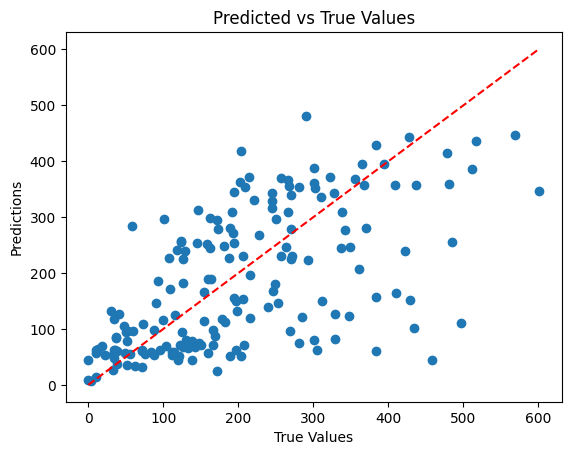

In [33]:
#plot predicted vs true
labels = labels * 100
predictions = predictions * 100
plt.scatter(labels, predictions)
plt.xlabel("True Values")
plt.ylabel("Predictions")
plt.title("Predicted vs True Values")
plt.plot([min(labels), max(labels)], [min(labels), max(labels)], 'r--') # line y=x
plt.show()

In [15]:
per_sample_pred

{'15700.hip.TSU.body1.spr2023.day5': [2.156426429748535, 1.0916666984558105],
 '15700.hip.UTK.body4.sum2023.day20': [3.9699745178222656, 5.113888740539551],
 '15700.hip.UTK.body1.spr2023.day8': [0.8796699047088623, 1.3888888359069824],
 '15700.hip.UTK.body2.spr2023.day14': [2.4020166397094727, 2.027777671813965],
 '15700.hip.CMU.body1.spr2023.day17': [1.6434438228607178, 1.5916666984558105],
 '15700.hip.UTK.body4.sum2023.day14': [3.4637022018432617, 3.549999952316284],
 '15700.hip.TSU.body3.sum2023.day11': [4.3551130294799805, 2.8972222805023193],
 '15700.hip.UTK.body1.spr2023.day11': [1.0831198692321777, 1.8277777433395386],
 '15700.hip.CMU.body6.fall2023.day20': [3.119513750076294, 2.2138888835906982],
 '15700.hip.UTK.body2.spr2023.day8': [0.8747169375419617, 1.149999976158142],
 '15700.hip.UTK.body1.spr2023.day2': [1.9989604949951172, 0.3472222089767456],
 '15700.hip.CMU.body1.spr2023.day11': [3.0615828037261963, 1.0777777433395386],
 '15700.hip.UTK.body3.sum2023.day17': [3.48824548

total donors in test set:  31
Per donor predictions:


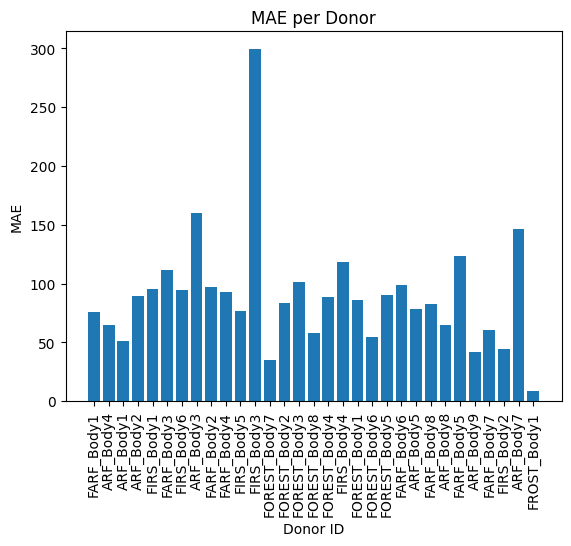

Per season predictions:


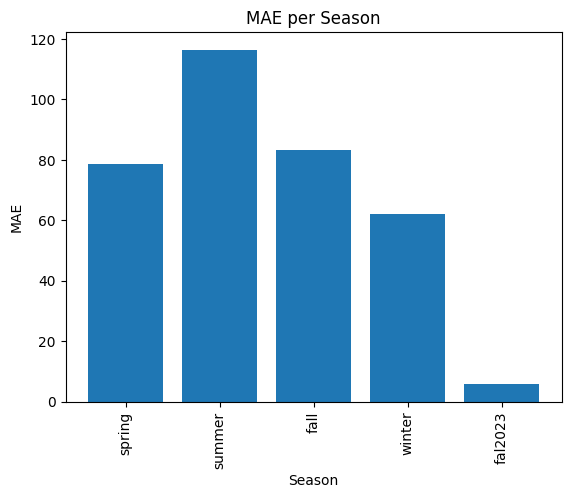

In [34]:
# per donor predictions
import numpy as np
per_donor_pred = {}
for key, (pred, true) in per_sample_pred.items():

    
    donor_id = sample_to_donor[key]
    if donor_id not in per_donor_pred:
        per_donor_pred[donor_id] = []
    per_donor_pred[donor_id].append((pred, true))

print("total donors in test set: ", len(per_donor_pred))
print("Per donor predictions:")
avg_mae_per_donor = {}
# plot per donor predictions
for donor_id, preds in per_donor_pred.items():
    preds = np.array(preds)
    mae = mean_absolute_error(preds[:, 1]*100, preds[:, 0]*100)
    avg_mae_per_donor[donor_id] = mae

# bar plot of per donor mae
plt.bar(avg_mae_per_donor.keys(), avg_mae_per_donor.values())
plt.xlabel("Donor ID")
plt.ylabel("MAE")
plt.title("MAE per Donor")
plt.xticks(rotation=90)
plt.show()
# group by season
season_to_preds = {}
for key, (pred, true) in per_sample_pred.items():

    season = metadata_all[metadata_all["sample_name"] == key]["season"].values[0]
    if season not in season_to_preds:
        season_to_preds[season] = []
    season_to_preds[season].append((pred, true))

print("Per season predictions:")
avg_mae_per_season = {}
# plot per season predictions
for season, preds in season_to_preds.items():
    preds = np.array(preds)
    mae = mean_absolute_error(preds[:, 1]*100, preds[:, 0]*100)
    avg_mae_per_season[season] = mae

# bar plot of per season mae
plt.bar(avg_mae_per_season.keys(), avg_mae_per_season.values())
plt.xlabel("Season")
plt.ylabel("MAE")
plt.title("MAE per Season")
plt.xticks(rotation=90)
plt.show()




In [37]:
max(avg_mae_per_donor, key=avg_mae_per_donor.get)

'FIRS_Body3'

In [40]:

#mean absolute error except FROST_Body3
mae_rest = 0
for donor_id, mae in avg_mae_per_donor.items():
    if donor_id != "FIRS_Body3" and donor_id != "FROST_Body1" :
        mae_rest += mae
print("Average MAE excluding FIRS_Body3 and FROST_Body1: ", mae_rest/(len(avg_mae_per_donor)-2))
print("Average MAE including FIRS_Body3: ", sum(avg_mae_per_donor.values())/len(avg_mae_per_donor))

Average MAE excluding FIRS_Body3 and FROST_Body1:  84.9589204473791
Average MAE including FIRS_Body3:  89.40309632151816


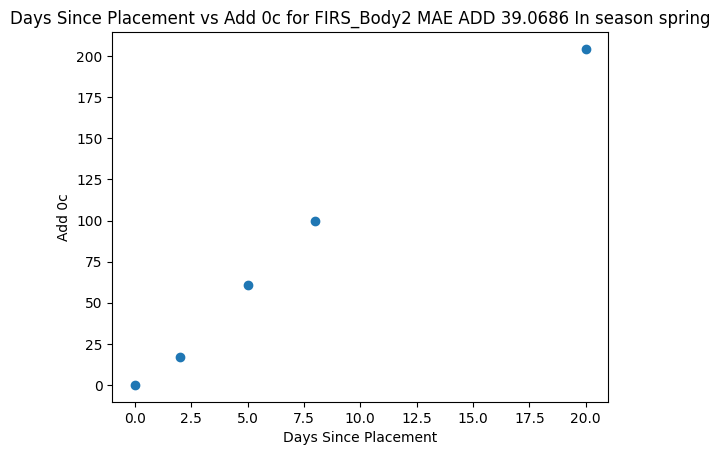

In [29]:
#### days since placement vs add_0c for best and worst body
body_id = "FIRS_Body2"
add_1 = metadata_all[metadata_all["host_subject_id"] == body_id]["add_0c"]
days_1 = metadata_all[metadata_all["host_subject_id"] == body_id]["days_since_placement"]
plt.scatter(days_1, add_1)
plt.xlabel("Days Since Placement")
plt.ylabel("Add 0c")
plt.title("Days Since Placement vs Add 0c for {} MAE ADD {:.4f} In season {}".format(body_id, avg_mae_per_donor[body_id], metadata_all[metadata_all["host_subject_id"] == body_id]["season"].values[0]))
plt.show()

In [22]:
for batch in test_loader:
    print(batch)

{'SampleID': ['15700.hip.TSU.body1.spr2023.day5', '15700.hip.UTK.body4.sum2023.day20', '15700.hip.UTK.body1.spr2023.day8', '15700.hip.UTK.body2.spr2023.day14'], 'embeddings': tensor([[[ 0.0200, -0.0058, -0.1100,  ..., -0.1095, -0.0284,  0.2091],
         [ 0.0194, -0.0393, -0.1287,  ..., -0.1524, -0.0008,  0.1622],
         [ 0.0414, -0.0991,  0.0086,  ..., -0.0655, -0.0220,  0.1151],
         ...,
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000]],

        [[-0.0566, -0.1957, -0.1841,  ..., -0.0970,  0.1292,  0.0293],
         [ 0.0200, -0.0058, -0.1100,  ..., -0.1095, -0.0284,  0.2091],
         [-0.0627, -0.0698, -0.0465,  ..., -0.0584,  0.1653,  0.1143],
         ...,
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
         [ 0.0